# Max-t permutation test: baseline vs. post-patching

Which channels, in which frequency bands, are reconstructed differently after patching? One paired test per channel × band, corrected for multiple comparisons over all of them at once.

**Data.** Metrics of `time_window` (`analysis`: post-stimulus patch 0 … 0.4 s, pre-stimulus patch −1.0 … −0.6 s), all folds of `model_name` (requires `run_inference.py --postpatch` outputs). `contrast` selects the tested difference, every one post-patching − baseline:
- `stimulus_locked`: (post − pre patch) post-patching − (post − pre patch) baseline. The pre-stimulus patch of the same trials is each session's reference.
- `post`: the post-stimulus patch alone (the *combined* contrast of `plasticity_plotting.ipynb`: session-wide and stimulus-locked changes together).
- `pre`: the pre-stimulus patch alone (session-wide, non-stimulus-locked changes only).

**Method: subject-level paired sign-flip permutation test with max-t correction**
1. Per subject, session, channel and band (+ all bands): average the log of the trials' error (`plot_data_processing.calc_subject_channel_band_means`). Errors are positive and right-skewed, and session differences in them are closer to proportional than additive. Trials in which a channel was interpolated are left out of that channel's mean. A metric with `None` in `metrics` is averaged without a log (e.g. signed error, already in dB and possibly negative).
2. Per subject: post-patching − baseline of the contrast in every cell, i.e. a log ratio for logged metrics. For `stimulus_locked`, each session's value is post − pre patch first, so the difference is (post − pre) post-patching − (post − pre) baseline (with a log: a log ratio of the post / pre ratios). This gives a subjects × cells matrix and one paired t = mean / (SD / √n) per cell.
3. Null distribution: flip the sign of each subject's whole row at random, recompute all t-values and keep the maximum |t|, `n_permutations` times (`core.permutation_test.max_t_sign_flip_test`). The observed signs count as one permutation, so p = (1 + #{max |t| ≥ |t_obs|}) / (n_permutations + 1).

Flipping whole rows keeps the correlation between cells (neighbouring channels, overlapping bands, metrics), so the correction is exact for this dependence, and much less conservative than Bonferroni.

**Design decisions beyond the specification**
- **Step-down max-t (Westfall & Young) decides significance.** The single-step test compares every |t| with the maximum over all cells. The step-down test compares the *k*-th largest |t| only with the maximum over the cells with smaller or equal |t|. It controls the family-wise error rate just as strongly and is never less powerful. Both p-values are reported.
- **All metrics form one family.** MAE and level error are tested in a single max-t over every metric × band × channel cell, so the family-wise error rate holds over every claim of this notebook. The two metrics are strongly correlated, which the max-t takes into account, so the second metric costs little power. Set `metrics` to MAE alone to test only MAE.
- **Log per metric.** MAE: mean of the trial logs (the log of the geometric mean), robust to single outlier trials. Level error: log of the subject mean. A trial's level error is the absolute value of a difference close to 0, so single trials come close to 0 and their logs have a long negative tail. A subject's mean over many trials stays well away from 0.
- **Stimulus-locked contrast.** Cap refit, impedance, drift and tonic (non-stimulus-locked) changes shift the pre- and post-stimulus patches of a session alike and cancel to first order. What remains is the change of the stimulus-locked part. The two patches go through the model in separate forward passes with their own wavelet targets, so they share no data. Changes that are not additive across the patches (e.g. a refit that scales a channel's evoked response more than its ongoing activity) don't cancel completely.
- **"all bands" stays in the family.** It largely repeats the four bands, and redundant (correlated) cells cost the max-t little.
- **Cell-level, not cluster-level inference.** A cluster permutation test is more sensitive to spatially extended effects, but it only supports the claim that a cluster contains *some* effect, not that a particular channel or band changed. The question here is about particular channels and bands.
- **Missing values.** A subject without a value in a cell (the channel interpolated in every trial of one session) is left out of that cell only. Sign-flipping whole rows stays a valid permutation. Cells with fewer than `min_subjects` subjects are left out of the family.

**Assumption.** Under H0 every subject's differences are symmetric around 0 (exchangeable signs). The log makes this much more plausible: see the skewness check.

**Reading the results.** Positive t = the error *increases* after patching (worse reconstruction). Changes of logged metrics are reported in %, 100 · (exp(mean log difference) − 1) (for `stimulus_locked`: of the post / pre ratio), changes of unlogged metrics in their own unit (dB). Signed error (output − target): positive t = after patching the model predicts the channel higher relative to its true level, i.e. the true level fell relative to what the visible channels predict; negative t = the true level rose.

In [183]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.stats import skew

from core import io, plotting, settings, utils
from core import plot_data_processing as data_processor
from core.permutation_test import max_t_sign_flip_test

In [184]:
model_name = "masking_10_19_2"
conditions = ["global"]  # stimulus types, None loads all
time_window = "analysis"  # key of settings.METRIC_WINDOWS whose metrics are tested
# tested contrast of the subject means, every one post-patching - baseline:
# "stimulus_locked": (post - pre patch) post-patching - (post - pre patch) baseline, session-wide shifts cancel to first order
# "post": post-stimulus patch alone (session-wide + stimulus-locked), "pre": pre-stimulus patch alone (session-wide only)
contrast = "stimulus_locked"
exclude_left_patched = True  # excludes the left-eye-dominant subjects of eye_dominance.csv
exclude_right_patched_lefties = True  # excludes the left-eye-dominant subjects of rightpatch_eye_dominance.csv (right-eye patching from STMD35 on)
exclude_button_press = False  # excludes the subjects of the button-press paradigm (before NO_PRESS_FROM_SUBJECT)

# tested metrics, all in one family, and how each one's trials are averaged into a subject mean:
# "mean_of_logs" (log of the geometric mean), "log_of_mean" (log of the arithmetic mean) or None (arithmetic mean, no log)
metrics = {"signed_error": None}
n_permutations = 10000
alpha = 0.05  # family-wise error rate
seed = 0  # seed of the random sign flips, for reproducible p-values
min_subjects = 10  # cells with fewer subjects with values in both sessions are left out of the family

In [185]:
bands = list(settings.FREQ_BANDS.keys())
band_keys = [*bands, data_processor.ALL_BANDS]

# patches every contrast needs, and its label in titles
CONTRAST_PATCHES = {"stimulus_locked": ("pre", "post"), "post": ("post",), "pre": ("pre",)}
CONTRAST_LABELS = {"stimulus_locked": "stimulus-locked: (post - pre stimulus) post-patching - baseline",
                   "post": "post-stimulus patch: post-patching - baseline",
                   "pre": "pre-stimulus patch: post-patching - baseline"}
if contrast not in CONTRAST_PATCHES:
    raise ValueError(f"Unknown contrast '{contrast}', expected one of {list(CONTRAST_PATCHES)}")
patches = CONTRAST_PATCHES[contrast]
contrast_label = CONTRAST_LABELS[contrast]
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]

exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))
if exclude_button_press:
    exclude_subjects.extend(subj for subj in io.get_stored_subject_names(settings.DATA_ROOT)
                            if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press")

# file names carry the contrast, the window and the excluded groups, the folder the model and the stimulus types (as in plasticity_plotting.ipynb)
excluded_groups = [group for group, excluded in [("left", exclude_left_patched), ("rightlefties", exclude_right_patched_lefties),
                                                 ("buttonpress", exclude_button_press)] if excluded]
file_suffix = f"{contrast}_window_{time_window}" + (f"_excl_{'_'.join(excluded_groups)}" if excluded_groups else "")
plot_root = settings.PLOT_INFERENCE / model_name / ("_".join(conditions) if conditions else "all_conditions") / "max_t_permutation"

### Load the patches of all folds

In [186]:
# every numbered fold folder of the model holds the baseline and post-patching reconstructions of its test trials,
# both patches of every trial; trials[(session, patch)] for the patches of the contrast
fold_dirs = sorted((d for d in (settings.INFERENCE_DIR / model_name).iterdir() if d.name.isdigit()), key=lambda d: int(d.name))
trials = {(session, patch): [] for session in ("baseline", "postpatch") for patch in patches}
for fold_dir in fold_dirs:
    for (session, patch), session_trials in trials.items():
        session_trials.extend(io.load_inference_trials(fold_dir / f"{session}_reconstruction.h5", conditions=conditions,
                                                       exclude_subjects=exclude_subjects, window=time_window, stim_patch=patch))
print(f"{len(fold_dirs)} folds, {contrast_label}: " + ", ".join(f"{len(t)} {s} {p}-patch trials" for (s, p), t in trials.items()))

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

### Subject × cell matrix of the contrast

In [187]:
def paired_rows(session_means, subjects):
    # rows of the given subjects, in that order, of the means and trial counts of calc_subject_channel_band_means
    session_subjects, means, counts = session_means
    rows = [session_subjects.index(subject) for subject in subjects]
    return means[rows], counts[rows]


def contrast_diff(means_by_key, subjects):
    """
    Post-patching - baseline of the contrast per subject (rows in the order of subjects), channel and band, from the subject means
    of every (session, patch) key of means_by_key (outputs of calc_subject_channel_band_means). With both patches, each session's
    value is post - pre patch first. Returns the differences (subjects, channels, bands) and the trial counts of every mean used.
    """
    values, counts = {}, []
    for session in ("baseline", "postpatch"):
        rows = {patch: paired_rows(means_by_key[(session, patch)], subjects) for patch in patches}
        counts.extend(patch_counts for _, patch_counts in rows.values())
        values[session] = rows["post"][0] - rows["pre"][0] if len(patches) == 2 else rows[patches[0]][0]
    return values["postpatch"] - values["baseline"], counts


# per metric, session and patch: subjects, (log) subject means (subjects, channels, bands) and the number of trials in every mean
log_means = {metric: {key: data_processor.calc_subject_channel_band_means(key_trials, metric, bands, log=log)
                      for key, key_trials in trials.items()}
             for metric, log in metrics.items()}

# paired subjects: subjects with trials in both sessions (the same for every metric; both patches come from the same trials)
first_metric = log_means[next(iter(metrics))]
b_subjects = set.intersection(*(set(first_metric[("baseline", patch)][0]) for patch in patches))
p_subjects = set.intersection(*(set(first_metric[("postpatch", patch)][0]) for patch in patches))
subjects = sorted(b_subjects & p_subjects)

# contrast per subject and cell, every metric's (subjects, channels, bands) flattened into columns
diffs_by_metric, trial_counts = {}, []
for metric, means_by_key in log_means.items():
    diffs_by_metric[metric], metric_counts = contrast_diff(means_by_key, subjects)
    trial_counts.extend(metric_counts)
trial_counts = np.stack(trial_counts)
diffs = np.concatenate([d.reshape(len(subjects), -1) for d in diffs_by_metric.values()], axis=1)
cells = pd.MultiIndex.from_product([list(metrics), CH_NAMES, band_keys], names=["metric", "channel", "band"])

n_per_cell = np.isfinite(diffs).sum(axis=0)
print(f"contrast: {contrast_label}")
print(f"{len(subjects)} subjects with both sessions, {diffs.shape[1]} cells ({len(metrics)} metrics x {len(CH_NAMES)} channels x {len(band_keys)} bands)")
print(f"left out, only one session: {sorted(b_subjects ^ p_subjects) or 'none'}")
print(f"subjects per cell: {n_per_cell.min()} - {n_per_cell.max()}, fewest trials in a subject mean: {trial_counts[trial_counts > 0].min()}, "
      f"subject means without any trial (channel interpolated in the whole session): {np.sum(trial_counts == 0)}")

contrast: stimulus-locked: (post - pre stimulus) post-patching - baseline
47 subjects with both sessions, 115 cells (1 metrics x 23 channels x 5 bands)
left out, only one session: none
subjects per cell: 43 - 47, fewest trials in a subject mean: 1, subject means without any trial (channel interpolated in the whole session): 190


### Check: symmetry of the subject differences

The sign-flip test needs the subjects' differences to be symmetric around 0 under H0. Skewness per cell of the differences of the contrast of the raw subject means (arithmetic means) and of the tested differences (the log differences for logged metrics; for unlogged metrics both are the same). Even for symmetric data, the skewness of one cell scatters with SE ≈ √(6/N), so look at the mean over cells (≈ 0 if symmetric) and compare the median |skewness| with its value for symmetric data.

In [188]:
print(f"{'metric':12s} {'differences':12s} {'mean skewness':>14s} {'median |skewness|':>18s}")
for metric, log in metrics.items():
    raw_means = {key: data_processor.calc_subject_channel_band_means(key_trials, metric, bands) for key, key_trials in trials.items()}
    checked = [("raw", contrast_diff(raw_means, subjects)[0])]
    if log is not None:
        checked.append(("log", diffs_by_metric[metric]))
    for label, metric_diffs in checked:
        cell_skewness = np.asarray(skew(metric_diffs.reshape(len(subjects), -1), axis=0, nan_policy="omit"), dtype=float)
        print(f"{metric:12s} {label:12s} {np.nanmean(cell_skewness):+14.2f} {np.nanmedian(np.abs(cell_skewness)):18.2f}")
print(f"median |skewness| of symmetric data with N={len(subjects)}: about {0.674 * np.sqrt(6 / len(subjects)):.2f}")

metric       differences   mean skewness  median |skewness|
signed_error raw                   -0.00               0.27
median |skewness| of symmetric data with N=47: about 0.24


### Permutation test

In [189]:
result = max_t_sign_flip_test(diffs, n_permutations=n_permutations, seed=seed, min_subjects=min_subjects)
logged = np.array([metrics[metric] is not None for metric in cells.get_level_values("metric")])
results = pd.DataFrame({
    "n": result.n,
    "mean_diff": result.mean,  # mean subject difference of the contrast: a log ratio for logged metrics, in the metric's unit otherwise
    "change": np.where(logged, 100 * np.expm1(result.mean), result.mean),  # %: geometric mean (mean_of_logs) or mean (log_of_mean); dB: unlogged
    "change_unit": np.where(logged, "%", "dB"),
    "d_z": result.t / np.sqrt(result.n),
    "t": result.t,
    "p_single_step": result.p_single_step,
    "p_step_down": result.p_step_down,
}, index=cells)
results["significant"] = results["p_step_down"] <= alpha

critical_t = result.critical_t(alpha)
print(f"contrast: {contrast_label}")
print(f"{results['t'].notna().sum()} of {len(results)} cells tested, {n_permutations} sign flips, smallest possible p = {1 / (n_permutations + 1):.1e}")
print(f"critical |t| of the single-step test at FWER {alpha}: {critical_t:.2f}")
print(f"significant cells: {results['significant'].sum()} (step-down), {(results['p_single_step'] <= alpha).sum()} (single step)")

contrast: stimulus-locked: (post - pre stimulus) post-patching - baseline
115 of 115 cells tested, 10000 sign flips, smallest possible p = 1.0e-04
critical |t| of the single-step test at FWER 0.05: 3.74
significant cells: 0 (step-down), 0 (single step)


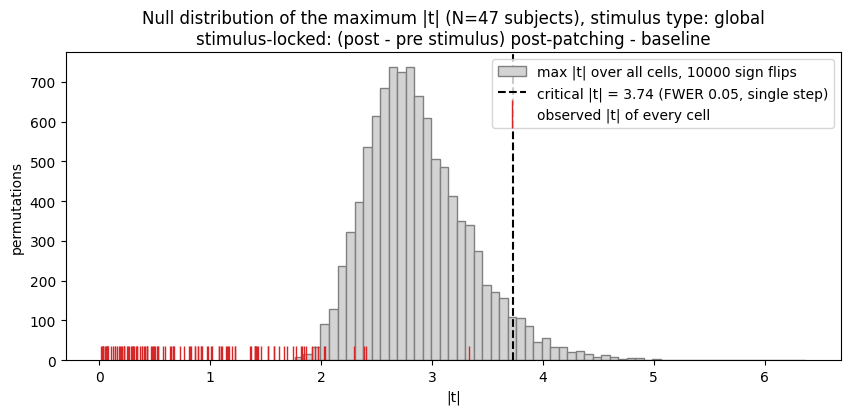

In [190]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(result.null_max, bins=60, color="lightgray", edgecolor="gray", label=f"max |t| over all cells, {n_permutations} sign flips")
ax.axvline(critical_t, color="black", linestyle="--", label=f"critical |t| = {critical_t:.2f} (FWER {alpha}, single step)")
observed = np.abs(results["t"].dropna().to_numpy())
ax.plot(observed, np.zeros_like(observed), "|", color="tab:red", markersize=20, label="observed |t| of every cell")
ax.set_xlabel("|t|")
ax.set_ylabel("permutations")
ax.set_title(f"Null distribution of the maximum |t| (N={len(subjects)} subjects), stimulus type: {', '.join(conditions) if conditions else 'all'}\n{contrast_label}")
ax.legend()
plotting.save_button(fig, save_dir=plot_root, default_name=f"null_distribution_{file_suffix}")
plt.show()

### Significant cells

Sorted by |t|, which is also the order of the step-down p-values. `change`: mean change of the contrast, in % for logged metrics, 100 · (exp(mean log difference) − 1), in dB otherwise (`change_unit`). `d_z`: mean / SD of the tested subject differences.

In [191]:
significant = results[results["significant"]].sort_values("t", key=np.abs, ascending=False)
display(significant.drop(columns="significant").round({"mean_diff": 4, "change": 2, "d_z": 2, "t": 2, "p_single_step": 4, "p_step_down": 4}))

,,,n,mean_diff,change,change_unit,d_z,t,p_single_step,p_step_down
metric,channel,band,,,,,,,,


In [192]:
# all cells, tested or not, as a CSV next to the figures
io.save_report(results.reset_index().to_dict("records"), f"max_t_results_{file_suffix}.csv", plot_root)

Saved 115 rows to outputs\plots\inference_plots\masking_10_19_2\global\max_t_permutation\max_t_results_stimulus_locked_window_analysis_excl_left_rightlefties.csv


### Overview: t of every cell

Rows: bands, columns: channels, one panel per metric. `*`: significant (step-down, FWER `alpha` over all panels). Blank cells were left out of the family.

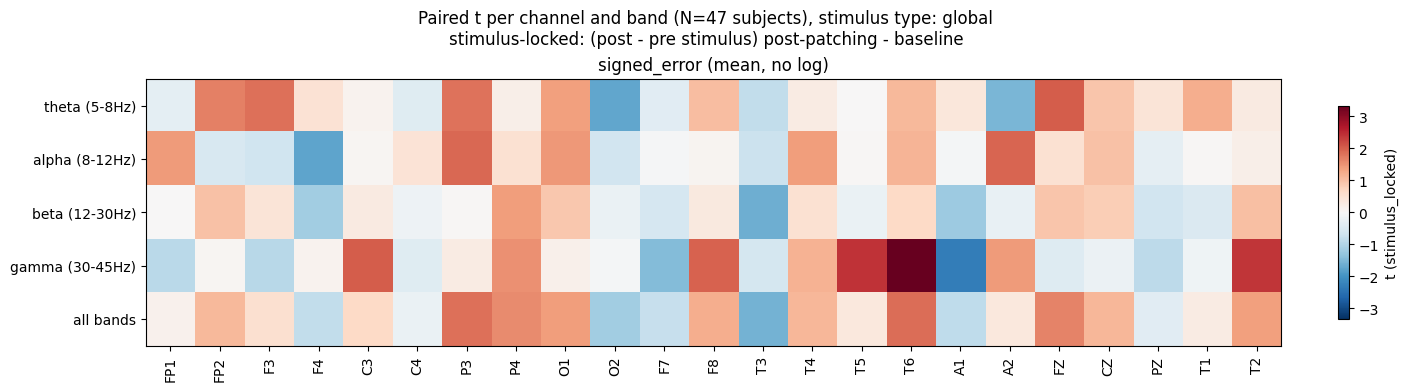

In [193]:
t_limit = np.nanmax(np.abs(results["t"]))
fig, axes = plt.subplots(len(metrics), 1, figsize=(14, 1 + 2.8 * len(metrics)), squeeze=False, layout="constrained")
for ax, metric in zip(axes[:, 0], metrics):
    metric_results = results.loc[metric]
    t_grid = metric_results["t"].unstack("channel").loc[band_keys, CH_NAMES].to_numpy(dtype=float)
    significant_grid = metric_results["significant"].unstack("channel").loc[band_keys, CH_NAMES].to_numpy(dtype=bool)
    im = ax.imshow(t_grid, cmap="RdBu_r", vmin=-t_limit, vmax=t_limit, aspect="auto")
    for row, col in zip(*np.nonzero(significant_grid)):
        ax.text(col, row, "*", ha="center", va="center", fontsize=14)
    ax.set_xticks(range(len(CH_NAMES)), CH_NAMES, rotation=90)
    ax.set_yticks(range(len(band_keys)), band_keys)
    ax.set_title(f"{metric} ({metrics[metric].replace('_', ' ') if metrics[metric] else 'mean, no log'})")
fig.colorbar(im, ax=axes, shrink=0.8, label=f"t ({contrast})")
fig.suptitle(f"Paired t per channel and band (N={len(subjects)} subjects), stimulus type: {', '.join(conditions) if conditions else 'all'}\n{contrast_label}")
plotting.save_button(fig, save_dir=plot_root, default_name=f"t_overview_{file_suffix}")
plt.show()

### Topomaps

Per metric: change in % or dB (top) and t (bottom) of every band, one symmetric colour scale per row. White dots: significant channels (step-down, FWER `alpha` over all metrics, bands and channels). Channels left out of the family are not drawn.

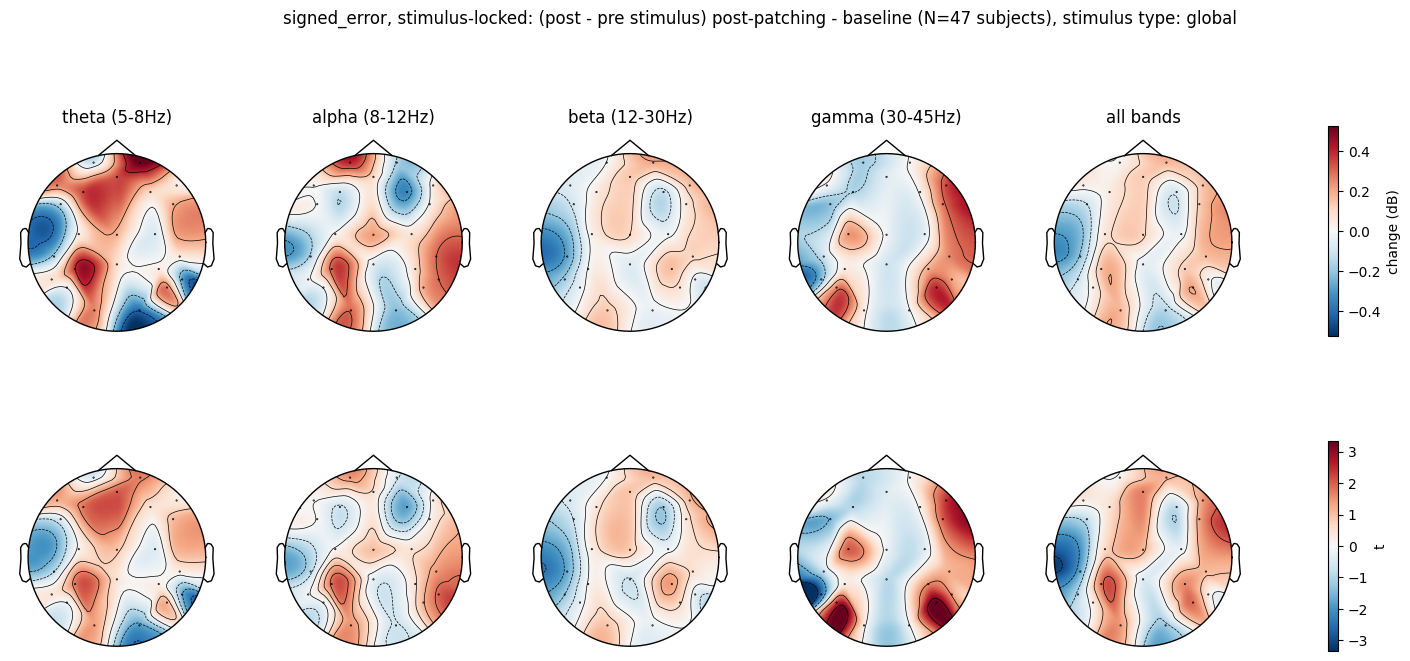

In [194]:
info = data_processor.create_topomap_info()  # 10-20 labels at the positions of the recording HydroCel electrodes, in CH_NAMES order
mask_params = dict(marker="o", markerfacecolor="white", markeredgecolor="black", linewidth=0, markersize=7)

for metric in metrics:
    metric_results = results.loc[metric]
    tested = metric_results[metric_results["t"].notna()]
    unit = "%" if metrics[metric] is not None else "dB"
    rows = [("change", f"change ({unit})", np.nanmax(np.abs(tested["change"]))), ("t", "t", t_limit)]

    fig, axes = plt.subplots(len(rows), len(band_keys), figsize=(4 * len(band_keys), 7.5))
    for col, band in enumerate(band_keys):
        band_results = metric_results.xs(band, level="band").loc[CH_NAMES]  # channel order of info
        keep = np.flatnonzero(band_results["t"].notna())
        images = []
        for row, (column, _, limit) in enumerate(rows):
            im, _ = mne.viz.plot_topomap(band_results[column].to_numpy(dtype=float)[keep], mne.pick_info(info, keep), axes=axes[row, col],
                                         show=False, vlim=(-limit, limit), cmap="RdBu_r",
                                         mask=band_results["significant"].to_numpy(dtype=bool)[keep], mask_params=mask_params)
            images.append(im)
        axes[0, col].set_title(band)
    for row, (_, label, _) in enumerate(rows):
        fig.colorbar(images[row], ax=axes[row], shrink=0.8, label=label)  # every panel of a row shares its colour scale
    fig.suptitle(f"{metric}, {contrast_label} (N={len(subjects)} subjects), stimulus type: {', '.join(conditions) if conditions else 'all'}", y=1.0)
    plotting.save_button(fig, save_dir=plot_root, default_name=f"{metric}_topomaps_{file_suffix}")
    plt.show()

### Check: comparison with MNE

`mne.stats.permutation_t_test` implements the single-step test on complete data. On the cells without missing subjects, both give the same t-values and, with different random sign flips, p-values that differ only by Monte Carlo error (SE ≈ √(p(1−p)/n_permutations), about 0.002 at p = 0.05).

In [195]:
complete = np.isfinite(diffs).all(axis=0) & results["t"].notna().to_numpy()
t_mne, p_mne, _ = mne.stats.permutation_t_test(diffs[:, complete], n_permutations=n_permutations, seed=seed, verbose=False)
check = max_t_sign_flip_test(diffs[:, complete], n_permutations=n_permutations, seed=seed + 1, min_subjects=min_subjects)
print(f"{complete.sum()} complete cells: t equal: {np.allclose(check.t, t_mne)}, "
      f"largest difference of the single-step p-values: {np.max(np.abs(check.p_single_step - p_mne)):.4f}")

70 complete cells: t equal: True, largest difference of the single-step p-values: 0.0087
